# Übung 4: Interaktive Datenvisualisierung

In dieser Übung vergleichst du statische Visualisierungen mit **plotnine** und interaktive Visualisierungen mit **Plotly**. Entscheidend ist nicht die Anzahl der Interaktionen, sondern ihr Beitrag zu einer konkreten Analysefrage.

> **Overview first, zoom and filter, then details-on-demand.** — Ben Shneiderman

## Aufbau und Zeitplanung

**Pflichtteil (ca. 60-75 Minuten)**

1. Histogramm: statisch und interaktiv
2. Bubble Chart: drei Variablen und Details-on-demand
3. Dropdown: Überblick und Kontinentfilter
4. Koordinierte Ansichten: gemeinsamer Filter für zwei Diagramme

**Wahlaufgaben:** Range Slider sowie Vergleich von Anteilsdiagrammen  
**Bonus:** Kennzahlenwechsel für ausgewählte Länder und Annotation

Die Aufgaben bauen aufeinander auf. Bearbeite zuerst den Pflichtteil.

## Lernziele

Nach der Bearbeitung kannst du:

- eine statische und eine interaktive Visualisierung für dieselbe Analysefrage erstellen und vergleichen,
- die Bestandteile einer Plotly-Figur als Daten-Traces, Layout und gegebenenfalls Frames erklären,
- Tooltips, Legenden, Dropdowns und Zeitfilter zielgerichtet einsetzen,
- mehrere Ansichten durch einen gemeinsamen Filter koordinieren,
- Nutzen und Grenzen einer Interaktion anhand der Analyseaufgabe begründen.

## Vorbereitung

Führe die Installationszelle nur aus, wenn ein Import in der folgenden Zelle fehlschlägt. Nach einer Installation kann ein Neustart des Kernels erforderlich sein.

In [155]:
# Bei Bedarf das Kommentarzeichen in der nächsten Zeile entfernen:
# %pip install pandas plotly plotnine statsmodels

In [156]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotnine as p9

## Daten laden und prüfen

Wir verwenden eine einzige, in Plotly enthaltene Version des Gapminder-Datensatzes. Die Daten enden 2007 und enthalten Beobachtungen in Fünfjahresschritten.

In [157]:
df = px.data.gapminder()
year = 2007
df_2007 = df.loc[df["year"] == year].copy()

print(f"Zeilen: {len(df):,}")
print(f"Länder: {df['country'].nunique()}")
print(f"Jahre: {df['year'].min()}–{df['year'].max()} in Schritten von {sorted(df['year'].unique())[:3]} …")
df_2007.head()

Zeilen: 1,704
Länder: 142
Jahre: 1952–2007 in Schritten von [np.int64(1952), np.int64(1957), np.int64(1962)] …


,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
11,Afghanistan,Asia,2007,43.828,31889923,974.580338,AFG,4
23,Albania,Europe,2007,76.423,3600523,5937.029526,ALB,8
35,Algeria,Africa,2007,72.301,33333216,6223.367465,DZA,12
47,Angola,Africa,2007,42.731,12420476,4797.231267,AGO,24
59,Argentina,Americas,2007,75.320,40301927,12779.379640,ARG,32


In [158]:
required_columns = {"country", "continent", "year", "lifeExp", "pop", "gdpPercap"}
assert required_columns.issubset(df.columns), "Erwartete Gapminder-Spalten fehlen."
assert len(df_2007) == df['country'].nunique(), "Für 2007 wird eine Zeile je Land erwartet."
print("Datenprüfung erfolgreich.")

Datenprüfung erfolgreich.


## Geführtes Beispiel: dieselbe Frage, zwei Werkzeuge

**Frage:** Wie hängt das BIP pro Kopf im Jahr 2007 mit der Lebenserwartung zusammen?

Die logarithmische X-Achse erleichtert den Vergleich stark unterschiedlich großer BIP-Werte. Die interaktive Version ergänzt Ländernamen im Hover.

In [159]:
fig = px.scatter(
    df_2007,
    x="gdpPercap",
    y="lifeExp",
    color="continent",
    hover_name="country",
    log_x=True,
    labels={
        "gdpPercap": "BIP pro Kopf (US-Dollar, Log-Skala)",
        "lifeExp": "Lebenserwartung (Jahre)",
        "continent": "Kontinent",
    },
    title="BIP pro Kopf und Lebenserwartung (2007)",
)
fig.show()

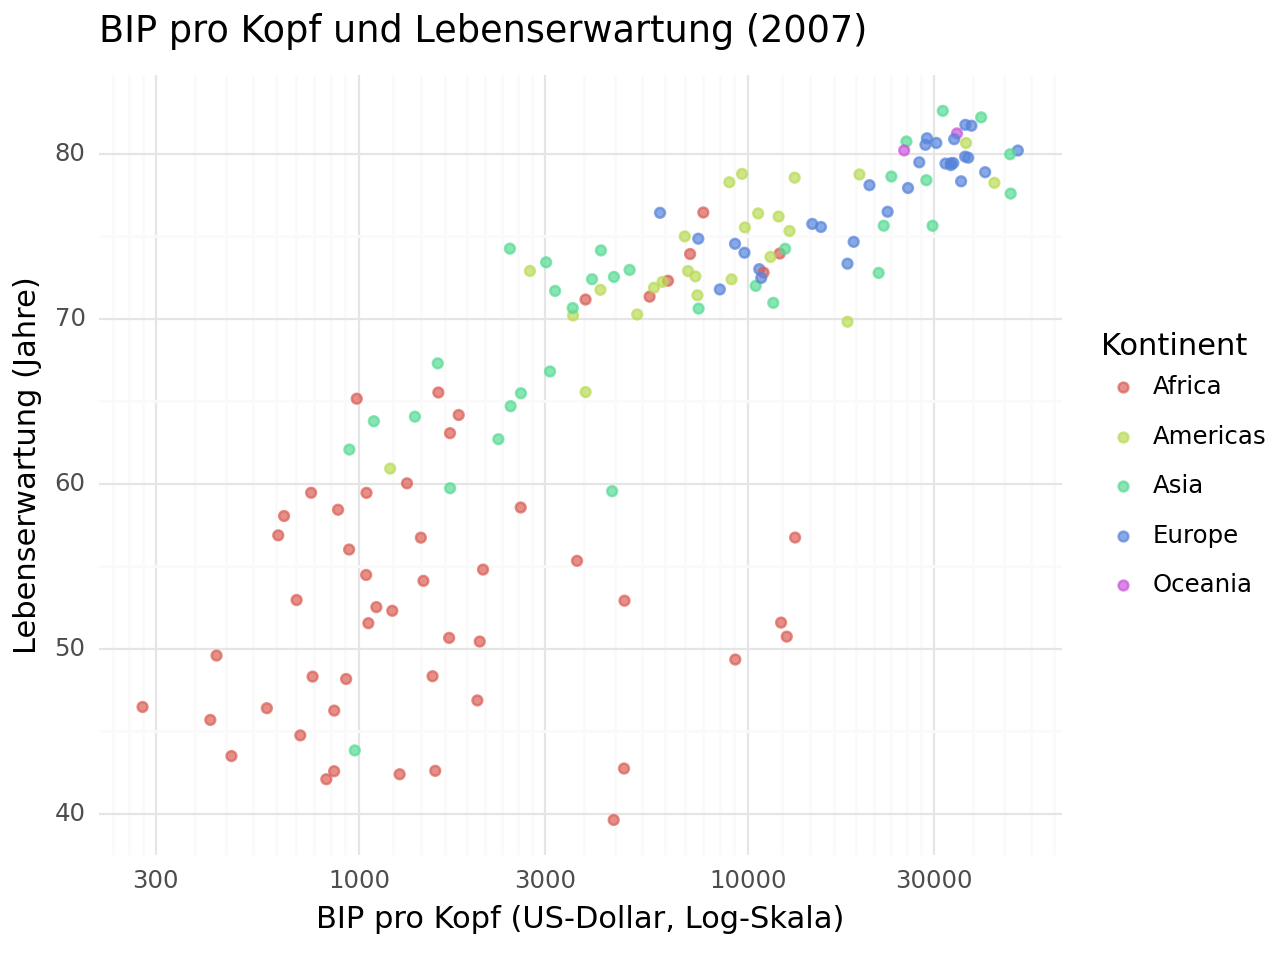

<Figure Size: (640 x 480)>

In [160]:
scatter_static = (
    p9.ggplot(df_2007, 
              p9.aes(
                  x="gdpPercap", 
                  y="lifeExp", 
                  color="continent")
                  )
    + p9.geom_point(alpha=0.7)
    + p9.scale_x_log10()
    + p9.labs(
        title="BIP pro Kopf und Lebenserwartung (2007)",
        x="BIP pro Kopf (US-Dollar, Log-Skala)",
        y="Lebenserwartung (Jahre)",
        color="Kontinent",
    )
    + p9.theme_minimal()
)
scatter_static

### Optional: Regressionslinie fachlich einordnen

Eine Regressionslinie beschreibt einen statistischen Zusammenhang, aber keine Kausalität. Durch `trendline_options=dict(log_x=True)` wird für das Modell der logarithmierte X-Wert verwendet; `log_x=True` steuert zusätzlich die Darstellung der Achse.

In [161]:
fig_reg = px.scatter(
    df_2007, 
    x="gdpPercap", 
    y="lifeExp", 
    hover_name="country",
    log_x=True, trendline="ols", trendline_options={"log_x": True},
    labels={"gdpPercap": "BIP pro Kopf (US-Dollar, Log-Skala)", "lifeExp": "Lebenserwartung (Jahre)"},
    title="Statistischer Zusammenhang zwischen BIP pro Kopf und Lebenserwartung (2007)",
)
fig_reg.show()

## Plotly-Mikrobeispiel: Dropdown und Sichtbarkeit

Plotly Express erzeugt ein `go.Figure`-Objekt. In diesem Beispiel erstellt `color="continent"` einen Trace je Kontinent. Ein Dropdown setzt für jeden Button eine Sichtbarkeitsmaske in derselben Reihenfolge wie `fig.data`.

In [162]:
demo = px.scatter(
    df_2007, 
    x="gdpPercap", 
    y="lifeExp", 
    color="continent",
    hover_name="country", 
    log_x=True, 
    title="Dropdown-Mikrobeispiel",
)
trace_names = [trace.name for trace in demo.data]
buttons = [
    dict(label="Alle Kontinente", method="update",
         args=[{"visible": [True] * len(demo.data)}, {"title": "Alle Kontinente"}])
]
for continent in trace_names:
    mask = [name == continent for name in trace_names]
    buttons.append(
        dict(label=continent, method="update",
             args=[{"visible": mask}, {"title": f"Kontinent: {continent}"}])
    )
demo.update_layout(
    updatemenus=[dict(buttons=buttons, direction="down", showactive=True, x=0, y=1.15)],
    margin=dict(t=110),
)
demo.show()

---
## Pflichtaufgabe 1: Verteilung der Lebenserwartung

Erstelle für 2007 ein statisches Histogramm mit plotnine und ein interaktives Histogramm mit Plotly. Verwende in beiden Grafiken dieselbe sinnvolle Anzahl an Klassen.

**Selbstcheck**

- Beide Diagramme verwenden dieselben Daten und dieselbe Klasseneinteilung.
- Achsen, Einheit, Jahr und Titel sind eindeutig.
- Du kannst erklären, welche zusätzliche Information Hover tatsächlich liefert.

In [163]:
# TODO: Statisches Histogramm mit plotnine
n_bins = 10

hist_static = (
    p9.ggplot(df_2007, p9.aes(x="lifeExp"))
    # + p9.geom_histogram(bins=..., ...)
    # + p9.labs(...)
    # + p9.theme_minimal()
)
# hist_static

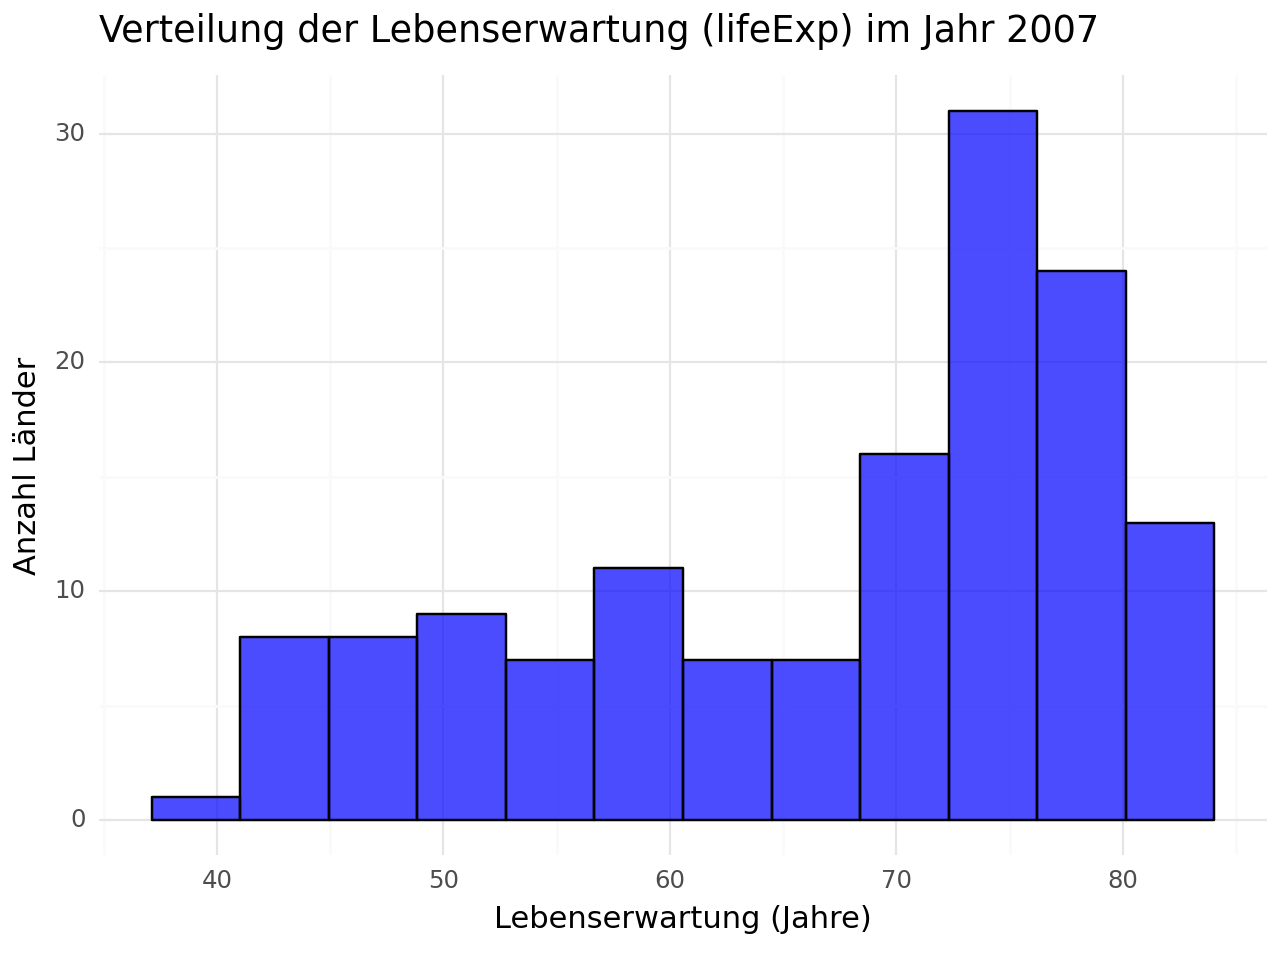

In [164]:
# Statisches Histogramm mit plotnine 
hist_static = (
        p9.ggplot(df_2007, p9.aes(x="lifeExp"))
        + p9.geom_histogram(bins=12, # Anzahl der Bins
                            fill = "blue", color = "black", alpha = 0.7) # Fallfarbe, Randfarbe und Transparenz
        + p9.labs(
            title="Verteilung der Lebenserwartung (lifeExp) im Jahr 2007",
            x="Lebenserwartung (Jahre)",
            y="Anzahl Länder"
        )
        + p9.theme_minimal()
    )

print(hist_static)

In [165]:
# TODO: Interaktives Histogramm mit Plotly Express
# hist_interactive = px.histogram(df_2007, x=..., nbins=n_bins, ...)
# hist_interactive.show()

In [166]:
# Interaktives Histogramm mit plotly.express
hist_interactive = px.histogram(
    df_2007,
    x="lifeExp",
    nbins=12,
    title="Verteilung der Lebenserwartung (lifeExp) im Jahr 2007 – interaktiv",
    labels={
        "lifeExp": "Lebenserwartung (Jahre)",
        "count": "Anzahl Länder"
    }
)

hist_interactive.show()

### Reflexion zu Aufgabe 1

1. Welche Form hat die Verteilung? Gibt es Hinweise auf mehrere Gruppen?
2. Ändert Interaktivität deine Interpretation oder nur die Bedienung?
3. Welche Darstellung würdest du für einen gedruckten Bericht wählen, welche für Exploration? Begründe.

### !!! Hinweis zu Bins plotly vs plotnine !!!

Trotz Festlegung der gleichen Anzahl an Bins über `n_bins` wurden in plotly und plotnine unterschiedliche Zahlen an Bins angezeigt. Korrekt mit der Anzahl  `nbins=12` ist plotnine. plotly arbeitet anders, da die Grenzen für die Bins anders festgelegt werden.

Siehe https://chatgpt.com/share/6ae0e25b-d76c-83eb-9db9-b915c9551119  

---
## Pflichtaufgabe 2: Bubble Chart

Untersuche 2007 den Zusammenhang zwischen BIP pro Kopf und Lebenserwartung. Kodiere Bevölkerung über die Punktfläche und Kontinent über Farbe. Erstelle eine statische und eine interaktive Variante.

**Achte besonders auf:** logarithmische X-Achse, sinnvolle Punktgrößen, Überdeckung und eine Legende mit klarer Einheit.

In [167]:
# TODO: Statischer Bubble Chart
bubble_static = (
    p9.ggplot(df_2007, p9.aes(x="gdpPercap", y="lifeExp", size="pop", color="continent"))
    # + p9.geom_point(alpha=...)
    # + p9.scale_x_log10()
    # + p9.scale_size_continuous(range=(... , ...))
    # + p9.labs(...)
    # + p9.theme_minimal()
)
# bubble_static

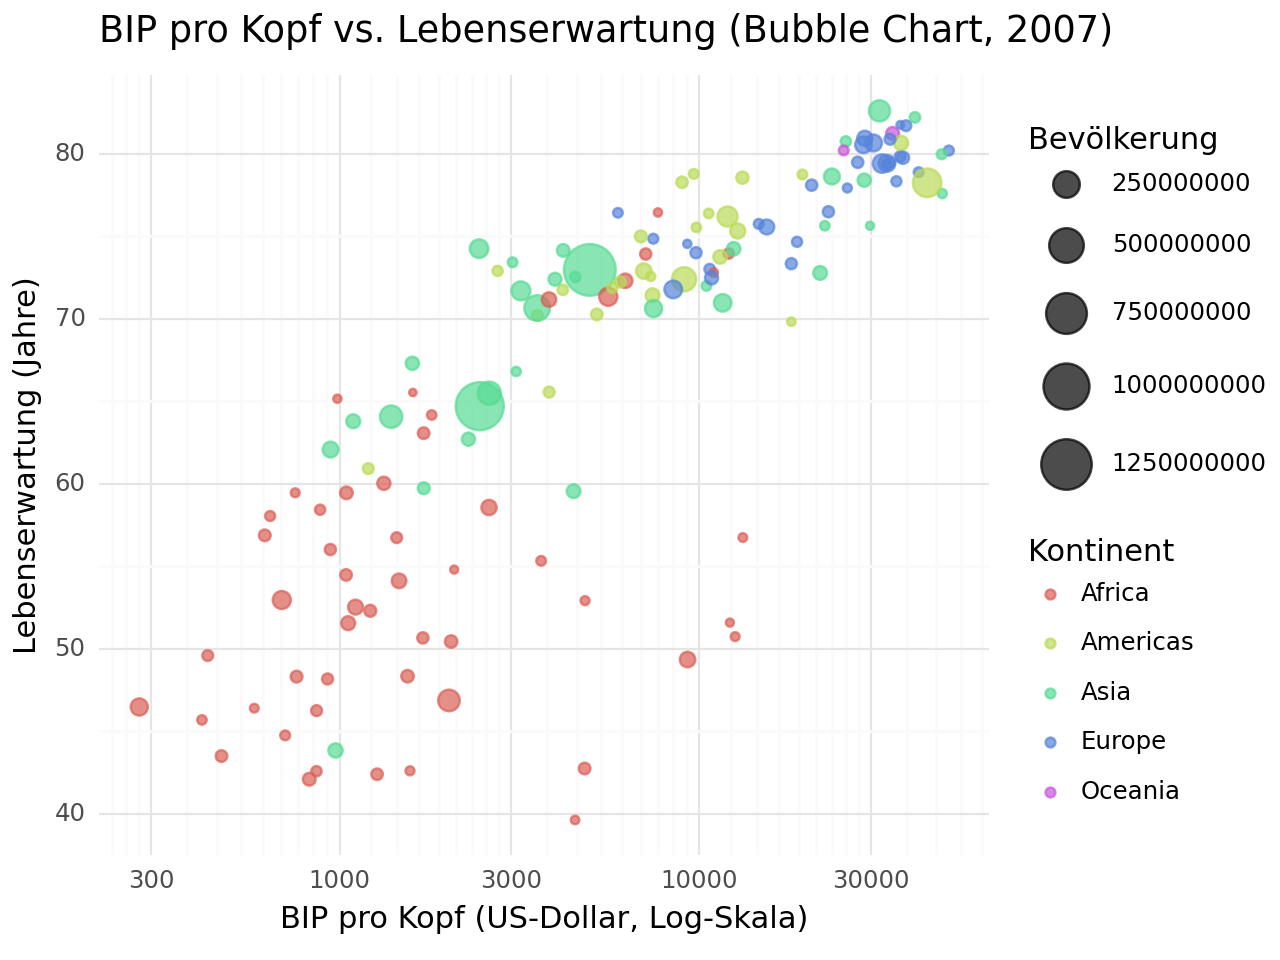

<Figure Size: (640 x 480)>

In [168]:
# Bubble Chart mit plotnine
bubble_static = (
    p9.ggplot(
        df_2007,
        p9.aes(x="gdpPercap", y="lifeExp", size="pop", color="continent"),
    )
    + p9.geom_point(alpha=0.7)
    + p9.scale_x_log10()
    + p9.scale_size_continuous(name="Bevölkerung", range=(1, 10))
    + p9.labs(
        title="BIP pro Kopf vs. Lebenserwartung (Bubble Chart, 2007)",
        x="BIP pro Kopf (US-Dollar, Log-Skala)",
        y="Lebenserwartung (Jahre)",
        color="Kontinent",
    )
    + p9.theme_minimal()
)

bubble_static

In [169]:
# TODO: Interaktiver Bubble Chart
# bubble_interactive = px.scatter(
#     df_2007, x=..., y=..., size=..., color=..., hover_name=...,
#     log_x=True, size_max=..., labels=..., title=...,
# )
# bubble_interactive.show()

In [170]:
bubble_interactive = px.scatter(
    df_2007,
    x="gdpPercap",
    y="lifeExp",
    size="pop",
    color="continent", #Kontinent als Farbe
    hover_name="country", #Name des Landes beim Hovern
    log_x=True, #Logarithmische Skala für x-Achse
    title="BIP pro Kopf vs. Lebenserwartung (Bubble Chart, 2007) – interaktiv", 
    labels={
        "lifeExp": "Lebenserwartung (Jahre)",
        "gdpPercap": "BIP pro Kopf (log-Skala)"
    }
)

bubble_interactive.show()

### Reflexion zu Aufgabe 2

1. Welche Länder oder Gruppen fallen auf?
2. Welche Information wird durch die Punktgröße sichtbar, welche wird verdeckt?
3. Warum darfst du aus dem dargestellten Zusammenhang keine Kausalität ableiten?
4. Welche Hover-Felder sind für die Analyse wirklich relevant?

---
## Pflichtaufgabe 3: Kontinentfilter mit Dropdown

Übertrage das Dropdown-Mikrobeispiel auf deinen Bubble Chart aus Aufgabe 2. Die Standardansicht zeigt alle Kontinente. Jede weitere Option zeigt genau einen Kontinent.

**Selbstcheck:** Der aktive Zustand ist erkennbar, die Option „Alle Kontinente“ stellt den Ausgangszustand wieder her und Hover zeigt mindestens Land, Bevölkerung und Jahr.

In [171]:
# Startfigur: ein Trace je Kontinent
fig_filter = px.scatter(
    df_2007, x="gdpPercap", y="lifeExp", size="pop", color="continent",
    hover_name="country", hover_data={"pop": ":,", "year": True},
    log_x=True, size_max=50, title="Alle Kontinente",
)

trace_names = [trace.name for trace in fig_filter.data]
buttons = []

# TODO 1: Button „Alle Kontinente“ ergänzen.
# TODO 2: In einer Schleife je Kontinent eine Sichtbarkeitsmaske erzeugen.
# TODO 3: Dropdown mit update_layout(updatemenus=[...]) einsetzen.

# fig_filter.show()

In [172]:
# Basis-Scatterplot
fig_filter = px.scatter(df_2007, x="gdpPercap",y="lifeExp",
    color="continent", # 
    hover_name="country", # Name des Landes beim Hovern
    hover_data={"pop": True, "year": True, "continent": False, "gdpPercap": False, "lifeExp": False, "iso_alpha": True}, #Hover-Daten anpassen
    log_x=True,
    title=f"Lebenserwartung vs. BIP pro Kopf ({year}) – alle Kontinente"
)

# Layout anpassen
fig_filter.update_layout(
    xaxis_title="BIP pro Kopf (log-Skala)",
    yaxis_title="Lebenserwartung (Jahre)"
)

# Kontinente in der Reihenfolge, wie sie in den Traces vorkommen
continent_order = [trace.name for trace in fig.data]

buttons = []

# Button 0: Alle Kontinente
buttons.append(
    dict(
        label="Alle Kontinente",
        method="update",
        args=[
            {"visible": [True] * len(fig.data)},  # alle Traces sichtbar
            {"title": f"Lebenserwartung vs. BIP pro Kopf ({year}) – alle Kontinente"}
        ],
    )
)

# Buttons 1..n: Einzelne Kontinente
for i, cont in enumerate(continent_order):
    visible = [False] * len(fig.data)
    visible[i] = True  # nur der i-te Kontinent sichtbar

    buttons.append(
        dict(
            label=cont,
            method="update",
            args=[
                {"visible": visible},
                {"title": f"Lebenserwartung vs. BIP pro Kopf ({year}) – {cont}"}
            ],
        )
    )

# Dropdown-Menü ins Layout einfügen
fig_filter.update_layout(
    updatemenus=[
        dict(
            type="dropdown",
            active=0,
            buttons=buttons,
            x=1.05,
            y=1.15,
            xanchor="right",
            yanchor="top",
        )
    ]
)

fig_filter.show()

---
## Pflichtaufgabe 4: Koordinierte Ansichten mit gemeinsamem Filter

Erstelle links einen Scatterplot und rechts ein Histogramm. Ein gemeinsames Dropdown filtert beide Ansichten nach Kontinent.

> Dies ist **koordinierte Filterung**, nicht echtes Brushing & Linking. Beim Brushing würde eine direkte Auswahl von Punkten in einer Ansicht die zugehörigen Elemente der anderen Ansicht hervorheben.

Das Grundgerüst erzeugt die beiden Traces. Ergänze das Dropdown so, dass die X- und Y-Daten beider Traces gemeinsam aktualisiert werden.

In [173]:
filters = {"Alle Kontinente": df_2007}
filters.update({
    continent: df_2007.loc[df_2007["continent"] == continent]
    for continent in sorted(df_2007["continent"].unique())
})

fig_linked = make_subplots(
    rows=1, cols=2,
    subplot_titles=("BIP pro Kopf und Lebenserwartung", "Verteilung der Lebenserwartung"),
)
fig_linked.add_trace(
    go.Scatter(
        x=df_2007["gdpPercap"], y=df_2007["lifeExp"], mode="markers",
        text=df_2007["country"], name="Länder",
        hovertemplate="%{text}<br>BIP/Kopf: %{x:,.0f}<br>Lebenserwartung: %{y:.1f}<extra></extra>",
    ), row=1, col=1,
)
fig_linked.add_trace(
    go.Histogram(x=df_2007["lifeExp"], nbinsx=12, name="Verteilung"),
    row=1, col=2,
)

buttons = []
for label, subset in filters.items():
    # Die Listen in args entsprechen der Trace-Reihenfolge: Scatter, Histogramm.
    # TODO: Button mit method="update" und passenden x-/y-Listen ergänzen.
    pass

fig_linked.update_xaxes(type="log", title_text="BIP pro Kopf (US-Dollar)", row=1, col=1)
fig_linked.update_yaxes(title_text="Lebenserwartung (Jahre)", row=1, col=1)
# TODO: Dropdown einsetzen, Titel und oberen Rand anpassen.
# fig_linked.show()

In [174]:
# Lösung mit Drowndown-Menü und angepasstem Layout

filters = {"Alle Kontinente": df_2007}
filters.update({
    continent: df_2007.loc[df_2007["continent"] == continent]
    for continent in sorted(df_2007["continent"].unique())
})

fig_linked = make_subplots(
    rows=1, cols=2,
    subplot_titles=("BIP pro Kopf (US-Dollar) und Lebenserwartung",
                    "Verteilung der Lebenserwartung"),
)

fig_linked.add_trace(
    go.Scatter(
        x=df_2007["gdpPercap"],
        y=df_2007["lifeExp"],
        mode="markers",
        text=df_2007["country"],
        name="Länder",
        hovertemplate=(
            "%{text}<br>"
            "BIP/Kopf: %{x:,.0f}<br>"
            "Lebenserwartung: %{y:.1f}"
            "<extra></extra>"
        ),
    ),
    row=1, col=1,
)

fig_linked.add_trace(
    go.Histogram(
        x=df_2007["lifeExp"],
        nbinsx=12,
        name="Verteilung"
    ),
    row=1, col=2,
)

buttons = []

for label, subset in filters.items():
    # Die Listen entsprechen der Trace-Reihenfolge:
    # Trace 0 = Scatter, Trace 1 = Histogramm
    buttons.append(
        dict(
            label=label,
            method="update",
            args=[
                {
                    "x": [
                        subset["gdpPercap"],   # Scatter
                        subset["lifeExp"],     # Histogramm
                    ],
                    "y": [
                        subset["lifeExp"],     # Scatter
                        None,                  # Histogramm benötigt kein y
                    ],
                    "text": [
                        subset["country"],     # Scatter-Hover
                        None,
                    ],
                },
                {
                    "title": f"Gapminder 2007 – {label}"
                }
            ],
        )
    )

fig_linked.update_xaxes(
    type="log",
    title_text="BIP pro Kopf (US-Dollar)",
    row=1, col=1
)

fig_linked.update_yaxes(
    title_text="Lebenserwartung (Jahre)",
    row=1, col=1
)

fig_linked.update_layout(
    title="Einkommen und Lebenserwartung in 2007 – Alle Kontinente",
    updatemenus=[
        dict(
            buttons=buttons,
            direction="down",
            x=0.0,
            y=1.18,
            xanchor="left",
            yanchor="top",
        )
    ],
    margin=dict(t=130)
)

fig_linked.show()

### Zusatz: mit verlinkten Filters links <> rechts (brush & link)

In [175]:
# Ausgangsdaten
df_brush_link = df_2007.copy()

fig_linked = go.FigureWidget(
    make_subplots(
        rows=1,
        cols=2,
        subplot_titles=(
            "BIP pro Kopf und Lebenserwartung",
            "Verteilung der Lebenserwartung"
        )
    )
)
# Scatterplot
fig_linked.add_trace(
    go.Scatter(
        x=df_brush_link["gdpPercap"],
        y=df_brush_link["lifeExp"],
        mode="markers",
        text=df_brush_link["country"],
        customdata=df_brush_link.index,
        name="Länder",
        marker=dict(size=9),
        hovertemplate=(
            "%{text}<br>"
            "BIP/Kopf: %{x:,.0f}<br>"
            "Lebenserwartung: %{y:.1f}"
            "<extra></extra>"
        ),
    ),
    row=1,
    col=1
)

# Histogramm
fig_linked.add_trace(
    go.Histogram(
        x=df_brush_link["lifeExp"],
        nbinsx=12,
        name="Verteilung"
    ),
    row=1,
    col=2
)

fig_linked.update_xaxes(
    type="log",
    title_text="BIP pro Kopf (US-Dollar)",
    row=1,
    col=1
)

fig_linked.update_yaxes(
    title_text="Lebenserwartung (Jahre)",
    row=1,
    col=1
)

fig_linked.update_xaxes(
    title_text="Lebenserwartung (Jahre)",
    row=1,
    col=2
)

fig_linked.update_layout(
    title="Gapminder 2007 – Linked Brushing",
    dragmode="select",
    margin=dict(t=100),
)

scatter = fig_linked.data[0]
hist = fig_linked.data[1]


# 1. Auswahl LINKS -> Histogramm RECHTS aktualisieren
def update_from_scatter(trace, points, selector):

    if points.point_inds:
        subset = df.iloc[points.point_inds]

        with fig_linked.batch_update():
            hist.x = subset["lifeExp"]
    else:
        # Auswahl aufgehoben -> wieder alle Daten
        with fig_linked.batch_update():
            hist.x = df["lifeExp"]


scatter.on_selection(update_from_scatter)


# 2. Auswahl RECHTS -> Scatterplot LINKS aktualisieren
def update_from_histogram(trace, points, selector):

    if points.xs:

        # Bereich der Selektion im Histogramm bestimmen
        xmin = min(points.xs)
        xmax = max(points.xs)

        mask = df_brush_link["lifeExp"].between(xmin, xmax)

        selected_indices = list(
            df_brush_link.loc[mask].index.map(
                lambda i: df_brush_link.index.get_loc(i)
            )
        )

        with fig_linked.batch_update():
            scatter.selectedpoints = selected_indices

    else:
        with fig_linked.batch_update():
            scatter.selectedpoints = None


hist.on_selection(update_from_histogram)


fig_linked

FigureWidget({
    'data': [{'customdata': array([  11,   23,   35,   47,   59,   71,   83,   95,  107,  119,  131,  143,
                                    155,  167,  179,  191,  203,  215,  227,  239,  251,  263,  275,  287,
                                    299,  311,  323,  335,  347,  359,  371,  383,  395,  407,  419,  431,
                                    443,  455,  467,  479,  491,  503,  515,  527,  539,  551,  563,  575,
                                    587,  599,  611,  623,  635,  647,  659,  671,  683,  695,  707,  719,
                                    731,  743,  755,  767,  779,  791,  803,  815,  827,  839,  851,  863,
                                    875,  887,  899,  911,  923,  935,  947,  959,  971,  983,  995, 1007,
                                   1019, 1031, 1043, 1055, 1067, 1079, 1091, 1103, 1115, 1127, 1139, 1151,
                                   1163, 1175, 1187, 1199, 1211, 1223, 1235, 1247, 1259, 1271, 1283, 1295,
                      

### Reflexion zu Aufgabe 4

1. Welche Muster werden erst durch die Kombination beider Ansichten sichtbar?
2. Welche Information geht beim Filtern verloren?
3. Wie unterscheidet sich koordinierte Filterung von echtem Brushing?
4. Wie würdest du den aktiven Filter für eine Veröffentlichung noch deutlicher anzeigen?

---
# Wahlaufgaben

Bearbeite mindestens eine Wahlaufgabe, wenn du den Pflichtteil abgeschlossen hast.

## Wahlaufgabe 5: Zeitreihe mit Range Slider

Berechne die **ungewichtete mittlere Lebenserwartung der Länder** je Kontinent und Jahr. Erstelle ein Liniendiagramm mit Range Slider sowie Buttons für alle Jahre, die letzten 20 Jahre und die letzten 10 Jahre.

Beachte: Die Daten liegen nur alle fünf Jahre vor. Ein Zehnjahresfenster enthält deshalb nur wenige Zeitpunkte.

In [176]:
life_exp_by_continent = (
    df.groupby(["year", "continent"], as_index=False)["lifeExp"].mean()
)
life_exp_by_continent["year_date"] = pd.to_datetime(life_exp_by_continent["year"], format="%Y")

fig_time = px.line(
    life_exp_by_continent, x="year_date", y="lifeExp", color="continent", markers=True,
    labels={"year_date": "Jahr", "lifeExp": "Ungewichteter Ländermittelwert der Lebenserwartung"},
    title="Mittlere Lebenserwartung der Länder nach Kontinent",
)
# TODO: rangeslider sichtbar machen.
# TODO: rangeselector mit 10 Jahren, 20 Jahren und „Alle“ ergänzen.
# fig_time.show()

In [177]:
# Durchschnittliche Lebenserwartung nach Jahr und Kontinent berechnen
life_exp_by_continent = (
    df.groupby(["year", "continent"], as_index=False)["lifeExp"].mean()
)
life_exp_by_continent["year_date"] = pd.to_datetime(life_exp_by_continent["year"], format="%Y")


#Minimal- und Maximaljahr für die Buttons definieren
year_min = life_exp_by_continent['year'].min() 
year_max = life_exp_by_continent['year'].max() 

# Liniendiagramm mit Range Slider und Buttons für Zeitfenster
fig_time = px.line( life_exp_by_continent, # Berechnete Daten zur durchschnittlichen Lebenserwartung
    x="year", # x-Achse: Jahr
    y="lifeExp", # y-Achse: Lebenserwartung 
    color="continent", # Farbe: Kontinent
    markers=True, # Markierungen an den Datenpunkten
    title="Durchschnittliche Lebenserwartung nach Kontinent und Jahr",
    labels={
        "year": "Jahr",
        "lifeExp": "Lebenserwartung (Jahre)",
        "continent": "Kontinent"
    }
)

# Range Slider auf der X-Achse aktivieren 
fig_time.update_xaxes(rangeslider=dict(visible=True))

# Buttons für Zeitfenster definieren
buttons = []

# Button 1: Alle Jahre 
buttons.append(
    dict(
        label="Alle Jahre",
        method="relayout",
        args=[{
            "xaxis.range": [year_min, year_max]
        }]
    )
)

# Button 2: Letzte 20 Jahre 
buttons.append(
    dict(
        label="Letzte 20 Jahre",
        method="relayout",
        args=[{
            "xaxis.range": [max(year_min, year_max - 20), year_max]
        }]
    )
)

# Button 3: Letzte 10 Jahre
buttons.append(
    dict(
        label="Letzte 10 Jahre",
        method="relayout",
        args=[{
            "xaxis.range": [max(year_min, year_max - 10), year_max]
        }]
    )
)

# Buttons ins Layout einfügen
fig_time.update_layout(
    updatemenus=[
        dict(
            type="buttons",
            direction="right",
            x=0.5,
            y=1.15,
            xanchor="center",
            yanchor="top",
            buttons=buttons,
            showactive=True
        )
    ]
)

fig_time.show()

## Wahlaufgabe 6: Bevölkerungsanteile vergleichen

Aggregiere die Bevölkerung 2007 nach Kontinent. Vergleiche:

1. Treemap,
2. Donut Chart,
3. Pie Chart

Pie und Donut verwenden dieselbe Winkelkodierung. Entscheide anhand einer konkreten Zielgruppe, welche Darstellung du empfehlen würdest.

In [178]:
population_by_continent = (
    df_2007.groupby("continent", as_index=False)["pop"].sum()
    .sort_values("pop", ascending=False)
)
population_by_continent["percent"] = (
    population_by_continent["pop"] / population_by_continent["pop"].sum() * 100
)
population_by_continent

,continent,pop,percent
2,Asia,3811953827,60.981376
0,Africa,929539692,14.870224
1,Americas,898871184,14.379608
3,Europe,586098529,9.376057
4,Oceania,24549947,0.392735


In [179]:
# TODO: Erzeuge mind zwei einzelne Figuren oder eine Figur mit umschaltbaren Traces.
# Hinweise: go.Treemap(...), go.Pie(hole=0.5, ...), go.Bar(orientation="h", ...)
# Zeige im Hover absolute Bevölkerung und Prozentanteil.

In [180]:
# Daten für 2007 aggregieren (Summe der Bevölkerung pro Kontinent)
df_agg = (
    df_2007
    .groupby("continent", as_index=False)["pop"]
    .sum()
    .sort_values("pop", ascending=False)
)

# Prozentanteile berechnen
total_pop = df_agg["pop"].sum()
df_agg["percent"] = df_agg["pop"] / total_pop * 100

continents = df_agg["continent"]
values = df_agg["pop"]
percents = df_agg["percent"]

# Labels für die Treemap mit Prozentanteil
hover_text_treemap = [
    f"{cont}<br>Bevölkerung: {val:,}<br>Anteil: {pct:.2f}%"
    for cont, val, pct in zip(continents, values, percents)
]

# Figure mit drei Diagrammtypen
fig = go.Figure()

# Trace 0: Treemap (mit Prozent)
fig.add_trace(
    go.Treemap(
        labels=continents,
        parents=[""] * len(continents),
        values=values,
        textinfo="label+percent entry",
        hovertext=hover_text_treemap,
        hoverinfo="text",
        name="Treemap",
        visible=True
    )
)

# Trace 1: Pie Chart
fig.add_trace(
    go.Pie(
        labels=continents,
        values=values,
        name="Pie",
        visible=False,
        hole=0.0,
        hovertemplate="Kontinent: %{label}<br>Anteil: %{percent}<extra></extra>"
    )
)

# Trace 2: Donut Chart
fig.add_trace(
    go.Pie(
        labels=continents,
        values=values,
        name="Donut",
        visible=False,
        hole=0.5,
        hovertemplate="Kontinent: %{label}<br>Anteil: %{percent}<extra></extra>"
    )
)


# Buttons zum Umschalten
buttons = [
    dict(
        label="Treemap",
        method="update", # Update-Methode für die Sichtbarkeit der Traces
        args=[
            {"visible": [True, False, False]},
            {"title": f"Anteile der Kontinente an der Weltbevölkerung ({year}) – Treemap"}
        ],
    ),
    dict(
        label="Pie",
        method="update", # Update-Methode für die Sichtbarkeit der Traces
        args=[
            {"visible": [False, True, False]},
            {"title": f"Anteile der Kontinente an der Weltbevölkerung ({year}) – Pie Chart"}
        ],
    ),
    dict(
        label="Donut",
        method="update", # Update-Methode für die Sichtbarkeit der Traces
        args=[
            {"visible": [False, False, True]},
            {"title": f"Anteile der Kontinente an der Weltbevölkerung ({year}) – Donut Chart"}
        ],
    ),
]

# Layout anpassen
fig.update_layout(
    title=f"Anteile der Kontinente an der Weltbevölkerung ({year}) – Treemap",
    updatemenus=[
        dict(
            type="buttons",
            direction="right",
            x=0.5,
            y=1.15,
            xanchor="center",
            yanchor="top",
            showactive=True,
            buttons=buttons #Definierte Buttons werden hier eingebunden
        )
    ],
    height=500
)

# Visualisierung anzeigen
fig.show()


---
# Bonusaufgaben

Die folgenden Aufgaben kombinieren mehrere Plotly-Konzepte. Sie sind nicht Teil des Pflichtumfangs.

## Bonus 7: Ausgewählte Länder und wechselbare Kennzahl

Begrenze die Auswahl auf höchstens acht Länder. Erzeuge einen Trace je Land und ein Dropdown für `lifeExp`, `gdpPercap` und `pop`. Aktualisiere beim Kennzahlenwechsel auch Titel, Einheit und gegebenenfalls Achsenskalierung. Vermeide eine Legende mit allen 142 Ländern.

In [181]:
default_countries = ["Germany", "Austria", "Switzerland"]
country_data = df.loc[df["country"].isin(default_countries)].copy()
country_data["year_date"] = pd.to_datetime(country_data["year"], format="%Y")
metrics = {
    "lifeExp": ("Lebenserwartung", "Jahre", False),
    "gdpPercap": ("BIP pro Kopf", "US-Dollar", True),
    "pop": ("Bevölkerung", "Personen", False),
}

# TODO: Figure mit einem Trace je Land erstellen.
# TODO: Dropdown aktualisiert y-Daten, Titel, Achsentitel und log-Einstellung.
# TODO: Range Slider ergänzen.

In [182]:
# Daten laden & vorbereiten
df = px.data.gapminder()

# Jahr-Spalte in Datetime konvertieren, um die X-Achse korrekt darzustellen
df["year_date"] = pd.to_datetime(df["year"], format="%Y")

# Kurzer Blick auf die Daten
countries = sorted(df["country"].unique())

# Festlegung der Spalten, die per Dropdown gewählt werden können
metrics = {
    "lifeExp": "Lebenserwartung",
    "gdpPercap": "BIP pro Kopf",
    "pop": "Bevölkerung"
}

# Einstiegswerte für die Visualisierung
start_metric = "lifeExp"
default_countries = ["Germany", "Austria", "Switzerland"]

# Daten pro Land & Variable vorbereiten
x_data = []  # Jahresachsen pro Land
data_per_metric = {
    m: [] for m in metrics.keys()
    }  # y-Daten pro Variable & Land

for country in countries:
    df_c = df[df["country"] == country].sort_values("year")
    df_c["year_date"] = pd.to_datetime(df_c["year"], format="%Y")
    x_data.append(df_c["year_date"])
    for m in metrics.keys():
        data_per_metric[m].append(df_c[m])

# Figure initialisieren – ein Trace pro Land
fig = go.Figure()

# Daten pro Land vorbereiten und Traces hinzufügen
for i, country in enumerate(countries):
    # Nur Germany & Austria initial einblenden, Rest über Legende wählbar
    visible_state = True if country in default_countries else "legendonly"
    fig.add_trace(
        go.Scatter(
            x=x_data[i],
            y=data_per_metric[start_metric][i],
            mode="lines+markers",
            name=country,
            visible=visible_state,
            hovertemplate=(
                "Land: " + country +
                "<br>Jahr: %{x|%Y}" +
                "<br>Wert: %{y:.2f}<extra></extra>"
            )
        )
    )

# Dropdown-Menü für Variable 
metric_buttons = []
for metric_key, metric_label in metrics.items():
    metric_buttons.append(
        dict(
            label=metric_label,
            method="update",
            args=[
                # y-Daten aller Traces auf die gewählte Variable setzen
                {"y": data_per_metric[metric_key]},
                # Achsentitel & Plot-Titel anpassen
                {
                    "yaxis": {"title": metric_label},
                    "title": f"{metric_label} in ausgewählten Ländern"
                }
            ]
        )
    )

# Layout + Slider + Selector
fig.update_layout(
    title=f"{metrics[start_metric]} in ausgewählten Ländern",
    xaxis=dict(
        rangeselector=dict(
            buttons=list([
                dict(
                    count=20,
                    label="letzte 20 Jahre",
                    step="year",
                    stepmode="backward"
                ),
                dict(step="all", label="alle")
            ])
        ),
        rangeslider=dict(visible=True),
        type="date",
        title="Jahr"
    ),
    yaxis=dict(
        title=metrics[start_metric]
    ),
    updatemenus=[
        dict(
            type="dropdown",
            buttons=metric_buttons,
            x=1,
            y=1.2,
            xanchor="left",
            yanchor="top",
            showactive=True
        )
    ],
    height=500
)

fig.show()


## Bonus 8: Nigeria und Deutschland annotieren

Vergleiche die Bevölkerung von Nigeria und Deutschland. Bestimme aus den Daten das erste beobachtete Jahr, in dem Nigeria einen höheren Wert aufweist. Verwende nicht einfach eine vorgegebene Jahreszahl, sondern berechne sie reproduzierbar. Ergänze anschließend eine Annotation.

In [183]:
comparison = (
    df.loc[df["country"].isin(["Nigeria", "Germany"]), ["country", "year", "pop"]]
    .pivot(index="year", columns="country", values="pop")
)
first_overtake_year = comparison.index[comparison["Nigeria"] > comparison["Germany"]][0]
print("Erstes beobachtetes Jahr mit Nigeria > Deutschland:", first_overtake_year)

Erstes beobachtetes Jahr mit Nigeria > Deutschland: 1987


In [184]:
# TODO: Liniendiagramm erstellen und fig.add_annotation(...) verwenden.

In [185]:
# Daten laden
df = px.data.gapminder()

countries = sorted(df["country"].unique())
default_countries = ["Nigeria", "Germany"]

# Figure initialisieren – ein Trace pro Land
fig = go.Figure()

# Daten pro Land vorbereiten und Traces hinzufügen
for country in countries:
    df_c = df[df["country"] == country].sort_values("year")

    # Standardmäßig nur Nigeria & Deutschland anzeigen
    visible_state = True if country in default_countries else "legendonly"

    fig.add_trace(
        go.Scatter(
            x=df_c["year"],
            y=df_c["pop"],
            mode="lines+markers",
            name=country,
            visible=visible_state,
            hovertemplate=(
                "Land: " + country +
                "<br>Jahr: %{x}" +
                "<br>Bevölkerung: %{y:,}<extra></extra>"
            )
        )
    )

# Annotation: Nigeria überholt Deutschland (1987) 
# Filterung der Daten für Nigeria im Jahr 1987, um die Bevölkerungszahl in diesem Jahr zu erhalten
nigeria_1987 = df[(df["country"] == "Nigeria") & 
                  (df["year"] == 1987)].iloc[0]

# Annotation-Koordinaten
anno_x = nigeria_1987["year"]
anno_y = nigeria_1987["pop"]

fig.add_annotation(
    x=anno_x,
    y=anno_y,
    xanchor="center",
    yanchor="bottom",
    showarrow=True,
    arrowhead=2,
    arrowsize=1,
    arrowwidth=1.5,
    ax=40,
    ay=-40,
    text="1987: Nigeria überholt Deutschland <br> erstmalig bei der Bevölkerungszahl",
)

# Layout
fig.update_layout(
    title="Bevölkerungsentwicklung – Nigeria, Deutschland im Vergleich",
    xaxis_title="Jahr",
    yaxis_title="Bevölkerung",
    height=500
)

fig.show()


## Bonus 9: Bevölkerungsanteile in Europa berechnen

Filtere auf den Kontinent Europa und zeige die Anteile der Bevölkerung an der Gesamtbevölkerung in Europa. 

Vergleiche hierzu: 

1. Treemap,
2. Donut Chart,
3. sortiertes horizontales Balkendiagramm.

Pie und Donut verwenden dieselbe Winkelkodierung. Das Balkendiagramm ergänzt bewusst eine besser vergleichbare gemeinsame Skala. Entscheide anhand einer konkreten Zielgruppe, welche Darstellung du empfehlen würdest.

In [186]:
# Daten für 2007 in Europa aggregieren
df_eu = df[df["continent"] == "Europe"]
df_eu_2007 = df_eu[df_eu["year"] == year]

# Bevölkerung pro Land aggregieren und sortieren
df_agg = (
    df_eu_2007
    .groupby("country", as_index=False)["pop"]
    .sum()
    .sort_values("pop", ascending=False)
)

# Prozentanteile berechnen
total_pop = df_agg["pop"].sum()
df_agg["percent"] = df_agg["pop"] / total_pop * 100

countries = df_agg["country"]
values = df_agg["pop"]
percents = df_agg["percent"]

# Hover-Text für Treemap
hover_text_treemap = [
    f"{country}<br>"
    f"Bevölkerung: {val:,.0f}<br>"
    f"Anteil an Europa: {pct:.2f}%"
    for country, val, pct in zip(countries, values, percents)
]

# Figure erstellen
fig = go.Figure()

# Trace 1: Treemap
fig.add_trace(
    go.Treemap(
        labels=countries,
        parents=[""] * len(countries),
        values=values,
        textinfo="label+percent entry",
        hovertext=hover_text_treemap,
        hoverinfo="text",
        name="Treemap",
        visible=True
    )
)

# Trace 2: Pie Chart
fig.add_trace(
    go.Pie(
        labels=countries,
        values=values,
        name="Pie",
        visible=False,
        hole=0.0,
        hovertemplate=(
            "Land: %{label}"
            "<br>Anteil an Europa: %{percent}"
            "<extra></extra>"
        )
    )
)

# Trace 3: Bar Chart
fig.add_trace(
    go.Bar(
        x=countries,
        y=values,
        name="Bar",
        visible=False,
        hovertemplate=(
            "Land: %{x}"
            "<br>Bevölkerung: %{y:,.0f}"
            "<extra></extra>"
        )
    )
)

# Buttons zum Umschalten
buttons = [
    dict(
        label="Treemap",
        method="update",
        args=[
            {
                "visible": [True, False, False]
            },
            {
                "title": (
                    f"Bevölkerungsanteile der Länder "
                    f"in Europa ({year}) – Treemap"
                ),
                "xaxis.visible": False,
                "yaxis.visible": False
            }
        ]
    ),

    dict(
        label="Pie",
        method="update",
        args=[
            {
                "visible": [False, True, False]
            },
            {
                "title": (
                    f"Bevölkerungsanteile der Länder "
                    f"in Europa ({year}) – Pie Chart"
                ),
                "xaxis.visible": False,
                "yaxis.visible": False
            }
        ]
    ),

    dict(
        label="Bar",
        method="update",
        args=[
            {
                "visible": [False, False, True]
            },
            {
                "title": (
                    f"Bevölkerungsanteile der Länder "
                    f"in Europa ({year}) – Bar Chart"
                ),
                "xaxis.visible": True,
                "yaxis.visible": True,
                "xaxis.title.text": "Land",
                "yaxis.title.text": "Bevölkerung"
            }
        ]
    )
]

# Layout
fig.update_layout(
    title=(
        f"Bevölkerungsanteile der Länder "
        f"in Europa ({year}) – Treemap"
    ),

    # Initial werden die Achsen ausgeblendet,
    # da die Treemap als erstes angezeigt wird.
    xaxis=dict(
        visible=False
    ),

    yaxis=dict(
        visible=False
    ),

    updatemenus=[
        dict(
            type="buttons",
            direction="right",
            x=0.5,
            y=1.15,
            xanchor="center",
            yanchor="top",
            showactive=True,
            buttons=buttons
        )
    ],

    height=600
)

# Visualisierung anzeigen
fig.show()

---
## Abschlussreflexion

1. Bei welcher Aufgabe hat die Interaktion eine neue Einsicht ermöglicht?
2. Wo hat sie lediglich zusätzliche Bedienung erzeugt?
3. Welche Kernbotschaft muss auch ohne Hover oder Filter sichtbar bleiben?
4. Wo stößt das Mantra „Overview first, zoom and filter, then details-on-demand“ an Grenzen?
5. Welche Anpassung wäre für kleine Bildschirme oder Tastaturbedienung erforderlich?